# Objectives
Welcome to Lab 7 of Natural Language Processing. This notebook focuses on the **BERTopic topic modeling framework**.

Today's objectives are to:

1. Analyze the **initial results** from BERTopic's default settings:
    1. The clustered **TOPICS** and their representative terms.
    2. The DOCUMENTS and their topic distributions.
3. Based on your analysis, **improve the topics** using some of BERTopic's provided parameters and methods.
4. **Evaluate** and compare your BERTopic model with LDiA using **coherence and diversity**.

# Notebook Setup

## Packages
The amazing BERTopic package home page is [here](https://maartengr.github.io/BERTopic/index.html). BERTopic was created by [Maarten Grootendorst](https://www.maartengrootendorst.com/) with a [paper](https://arxiv.org/abs/2203.05794) published in 2022.

In [96]:
#| code-summary: 'Import packages'
# Dataset packages
from datasets import load_dataset

# Data packages
import pandas as pd
pd.set_option('display.max_colwidth', None) #default: 50 chars
pd.set_option('display.max_columns', None) #default: 20 columns
import numpy as np

# NLP packages
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
from bertopic import BERTopic
from gensim.models import CoherenceModel
import gensim.corpora as corpora

# NLP packages
import spacy
import gensim.downloader as api
from gensim.models import Word2Vec, KeyedVectors
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from langdetect import detect

import nltk
from nltk.corpus import stopwords

import torch
import seaborn
import matplotlib.pyplot as plt

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import hdbscan
import umap

from sentence_transformers import SentenceTransformer #https://huggingface.co/sentence-transformers/all-mpnet-base-v2

from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

from wordcloud import WordCloud

import gensim.corpora as corpora
import gensim

from gensim.models import CoherenceModel



## Moving Model and Data to GPU
It is generally faster to run on your GPU if available. This code checks for availability and subsequent code will move the model and data batches to the assigned device. (taken from lab 9)

In [2]:
if torch.cuda.is_available():
    device = torch.device('cuda') # NVIDIA GPU
elif torch.backends.mps.is_available():
    device = torch.device('mps') # Apple GPU
else:
    device = torch.device('cpu') # Fallback CPU
print('Using device:', device)

Using device: mps


# Datasets
Install the datasets from Huggingface. Needs to be done using read_parquet.

In [3]:
bladee   = pd.read_parquet("hf://datasets/huggingartists/bladee@refs/convert/parquet/default/train/0000.parquet")
yunglean = pd.read_parquet("hf://datasets/huggingartists/yung-lean@refs/convert/parquet/default/train/0000.parquet")
xxx   = pd.read_parquet("hf://datasets/huggingartists/xxxtentacion@refs/convert/parquet/default/train/0000.parquet")
lilpeep   = pd.read_parquet("hf://datasets/huggingartists/lil-peep@refs/convert/parquet/default/train/0000.parquet")
bladee["artist"]   = "bladee"
yunglean["artist"] = "yung lean"
xxx["artist"]   = "xxxtentacion"
lilpeep["artist"] = "lil peep"

In [4]:
df = pd.concat([bladee, yunglean, xxx, lilpeep], ignore_index=True)[["artist", "text"]]

## Cleaning choices made

In [5]:
df = df.drop_duplicates() #some songs are included multiple times 
# Source - https://stackoverflow.com/a/70771731
# Posted by Barth
# Retrieved 2026-11-14, License - CC BY-SA 4.0

df = df.replace("\s+", " ", regex=True).apply(lambda x: x.str.strip()) #Remove access white space
df['text'] = df['text'].str.lower()

df = df[~df["text"].str.startswith(("lyrics", "not available"), na=False)] #"lyrics from "

df = df[~df["text"].str.contains(("lyrics"), na=False)] # cleaning process after looking at database some just talking about the lyrics 

# Source - https://stackoverflow.com/a/56708633
# Posted by coldspeed95, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-14, License - CC BY-SA 4.0

df = df[df['text'].str.strip().astype(bool)] #remove empty rows 

df['text'] = df['text'].str.replace(r'\b(\w+)\s+\1,*\b', r'\1', regex=True, case=False) #songs so words like "yeah yeah yeah "
df['text'] = df['text'].str.replace(r'\ba+y+', r'', regex=True, case=False) #remove adlibs
df['text'] = df['text'].str.replace(r'\bo+h+', r'', regex=True, case=False) #remove adlibs

df = df[df["text"].apply(len)>20] #dataset included tweets and other short messages 

# Source - https://stackoverflow.com/a/67789744
# Posted by Ank, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-14, License - CC BY-SA 4.0

df = df[df['text'].apply(detect).eq('en')] #some songs by Bladee are in Swedish, and fan attribution to peep in Spanish and Russian 

<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
/var/folders/_d/jmptf6h503s9xxpwhlh2g6m00000gn/T/ipykernel_83777/2849055883.py:6: SyntaxWarning: invalid escape sequence '\s'
  df = df.replace("\s+", " ", regex=True).apply(lambda x: x.str.strip()) #Remove access white space


## Tokenizing

In [6]:
#from lab 2 
nlp = spacy.load('en_core_web_sm')

nltk.download("stopwords")  #changing custom stop words, because spacy was removing too many words to understand any context 
stop_words = set(stopwords.words("english"))

stop_words.update(["yeah", "nah", "mmm", "im", "like"])

#| code-summary: "spaCy tokenize on dataset"
#| code-fold: false
docs_as_tokens = list(nlp.pipe(df['text'])) # entire dataset
df['tokens_spacy'] = [
    [token.text for token in doc if not token.is_punct if token.text not in stop_words] # no normalization
    for doc in docs_as_tokens] # per-document
df[['text', 'tokens_spacy']].sample(2)

[nltk_data] Downloading package stopwords to /Users/aj/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,text,tokens_spacy
1178,"a one, two, three , , , , , , , , , ill stop the world when im with you nothin to hate, nothin to lose put down the loaded guns, and socialize with everyone ill stop the war when im with you so tell em, say , , , , , , , , ,","[one, two, three, , ill, stop, world, nothin, hate, nothin, lose, put, loaded, guns, socialize, everyone, ill, stop, war, tell, em, say]"
1870,"i was dying and nobody was there please dont cry, baby, life aint fair i was dying and nobody was there please dont cry, baby, life aint fair i run away from my problems i do the drugs when i want em i ran away from my momma dont bother me with no drama now im looking for a ghost girl i aint never gonna find her pain pills with my coke, girl you know i gotta get high first take me, away from here everybody so fake everybody so fake, i swear but i dont wanna go back there everybody so fake everybody act like they care take me, away from here everybody so fake everybody so fake, i swear everybody act like they care why the fuck do everybody act like they care? i was dying and nobody was there please dont cry, baby, life aint fair i was dying and nobody was there please dont cry, baby, life aint fair i run away from my problems i do the drugs when i want em i ran away from my momma dont bother me with no drama now im looking for a ghost girl i aint never gonna find her pain pills with my coke, girl you know i gotta get high first take me, away from here everybody so fake everybody so fake, i swear but i dont wanna go back there everybody so fake everybody act like they care take me, away from here everybody so fake everybody so fake, i swear everybody act like they care why the fuck do everybody act like they care?","[dying, nobody, please, nt, cry, baby, life, ai, nt, fair, dying, nobody, please, nt, cry, baby, life, ai, nt, fair, run, away, problems, drugs, want, em, ran, away, momma, nt, bother, drama, looking, ghost, girl, ai, nt, never, gon, na, find, pain, pills, coke, girl, know, got, ta, get, high, first, take, away, everybody, fake, everybody, fake, swear, nt, wanna, go, back, everybody, fake, everybody, act, care, take, away, everybody, fake, everybody, fake, swear, everybody, act, care, fuck, everybody, act, care, dying, nobody, please, nt, cry, baby, life, ai, nt, fair, dying, nobody, please, nt, cry, baby, life, ai, nt, ...]"


In [7]:
df["tokens_spacy"] = df["tokens_spacy"].apply(
    lambda items: [s for s in items if len(s) >= 3] #removing short tokens that aren't words
)

df = df[df["tokens_spacy"].apply(len)>20] #dataset included tweets and other short messages 


In [8]:
# Source - https://stackoverflow.com/a/66104513
# Posted by LePuppy, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-14, License - CC BY-SA 4.0

df.to_csv('cleaned_file.csv', index = False)

In [9]:
len(df[df['artist']=="bladee"])

279

In [10]:
len(df[df['artist']=="yung lean"])

242

In [11]:
len(df[df['artist']=="lil peep"])

479

In [12]:
len(df[df['artist']=="xxxtentacion"])

517

In [13]:
#want to delete rows to ensure 240 samples per artist 
np.random.seed(42)
df = pd.concat([df[df["artist"]=="bladee"].sample(n=240), df[df["artist"]=="yung lean"].sample(n=240), df[df["artist"]=="lil peep"].sample(n=240), df[df["artist"]=="xxxtentacion"].sample(n=240)])


## Sentiment Analysis using Vader before any embeddings

In [14]:

#sentiment analyzer
sid = SentimentIntensityAnalyzer()
for row in df:
    df['sentiment_score'] = df['text'].apply(lambda song: sid.polarity_scores(song)['compound'])

### Graphing Sentiment Analysis 

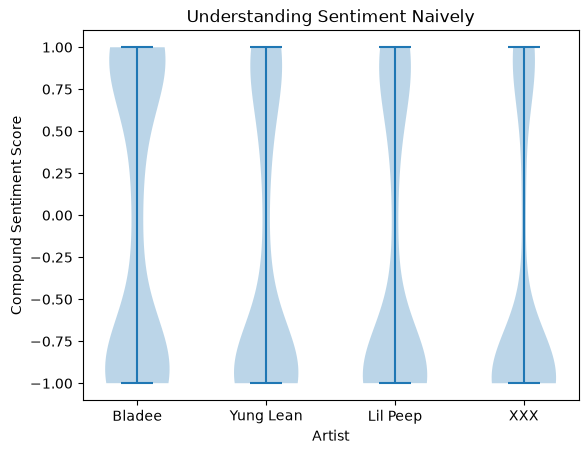

In [15]:

bladee_sentiment = df[df['artist']== 'bladee']
yunglean_sentiment = df[df['artist']== 'yung lean']
lilpeep_sentiment = df[df['artist']== 'lil peep']
xxx_sentiment = df[df['artist']== 'xxxtentacion']

data_to_chart = [bladee_sentiment["sentiment_score"], yunglean_sentiment["sentiment_score"], lilpeep_sentiment["sentiment_score"], xxx_sentiment["sentiment_score"]]
plt.violinplot(data_to_chart)

plt.xlabel('Artist')
plt.ylabel('Compound Sentiment Score')
plt.title('Understanding Sentiment Naively')
plt.xticks([1,2,3,4],["Bladee", "Yung Lean", "Lil Peep", "XXX"])
plt.show()

In [ ]:
# Not currently in use 


#model = SentenceTransformer('sentence-transformers/all-mpnet-base-v2')
#embeddings = model.encode(
#        docs,
#        batch_size=32,
#        show_progress_bar=True
#    )
#print(embeddings)


In [ ]:
# Not currently in use 
# Code augmented from https://github.com/dborrelli/chat-intents/blob/main/chatintents/chatintents.py with relevant Medium accredidaton at https://towardsdatascience.com/clustering-sentence-embeddings-to-identify-intents-in-short-text-48d22d3bf02e/
#n_neighbors = 15
#n_components = 5
#min_cluster_size = 5
#min_samples = 2
#random_state=42

#umap_embeddings = (umap.UMAP(n_neighbors=n_neighbors,n_components=n_components, metric='cosine',random_state=random_state).fit_transform(embeddings))

#clusters = (hdbscan.HDBSCAN(min_cluster_size=min_cluster_size, min_samples=min_samples, metric='euclidean', gen_min_span_tree=True, cluster_selection_method='eom').fit(umap_embeddings))


In [92]:
#https://agentbus.sh/posts/how-to-build-a-text-clustering-pipeline-with-embeddings-and-hdbscan/
docs = df['text'].tolist() # keep only 'text'
model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")
embeddings = model.encode(docs, batch_size=32, show_progress_bar=True)

reducer = umap.UMAP(n_components=10, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=42)
reduced = reducer.fit_transform(embeddings)
# For clustering (not visualization)
reducer_cluster = umap.UMAP(
    n_components=5,
    n_neighbors=10,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)

# For 2D visualization
reducer_viz = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
)

reduced_for_clustering = reducer_cluster.fit_transform(embeddings)
reduced_for_viz = reducer_viz.fit_transform(embeddings)

Batches: 100%|██████████| 30/30 [00:27<00:00,  1.08it/s]


In [93]:
#code ref: https://agentbus.sh/posts/how-to-build-a-text-clustering-pipeline-with-embeddings-and-hdbscan/
def extract_cluster_labels(documents, labels, top_n=5):
    unique_labels = set(labels)
    unique_labels.discard(-1)  # skip noise

    # Group documents by cluster
    cluster_docs = {}
    for label in unique_labels:
        cluster_docs[label] = " ".join(
            doc for doc, lbl in zip(documents, labels) if lbl == label
        )

    # Fit TF-IDF on the concatenated cluster texts
    corpus = [cluster_docs[label] for label in sorted(cluster_docs.keys())]
    vectorizer = TfidfVectorizer(stop_words="english", max_features=1000)
    tfidf_matrix = vectorizer.fit_transform(corpus)
    feature_names = vectorizer.get_feature_names_out()

    cluster_labels = {}
    for idx, label in enumerate(sorted(cluster_docs.keys())):
        scores = tfidf_matrix[idx].toarray().flatten()
        top_indices = scores.argsort()[-top_n:][::-1]
        top_terms = [feature_names[i] for i in top_indices]
        cluster_labels[label] = top_terms

    return cluster_labels

clusterer = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=7, metric="euclidean")
labels = clusterer.fit_predict(reduced)

topic_labels = extract_cluster_labels(docs, labels)
for cluster_id, terms in topic_labels.items():
    print(f"Cluster {cluster_id}: {', '.join(terms)}")


Cluster 0: moonlight, shine, uh, im, spotlight
Cluster 1: regrets, die, grim, reaper, instead
Cluster 2: im, got, like, flex, force
Cluster 3: im, like, merry, way, just
Cluster 4: im, gothboiclique, like, dont, slip
Cluster 5: im, hunnids, like, highway, dont
Cluster 6: im, let, know, dont, love
Cluster 7: im, aint, bitch, baby, love
Cluster 8: dont, im, know, love, like
Cluster 9: like, im, drain, try, dont
Cluster 10: im, bitch, like, dont, lil
Cluster 11: la, im, thaiboy, pour, million
Cluster 12: im, like, drain, feel, dont
Cluster 13: shawty, like, im, thc, hoverboard
Cluster 14: im, like, know, got, lean
Cluster 15: im, like, greggy, lean, got
Cluster 16: ghost, im, bitch, like, nigga
Cluster 17: dis, bih, designer, im, sip
Cluster 18: bitch, im, suck, fuck, like
Cluster 19: bitch, like, im, fuck, dick


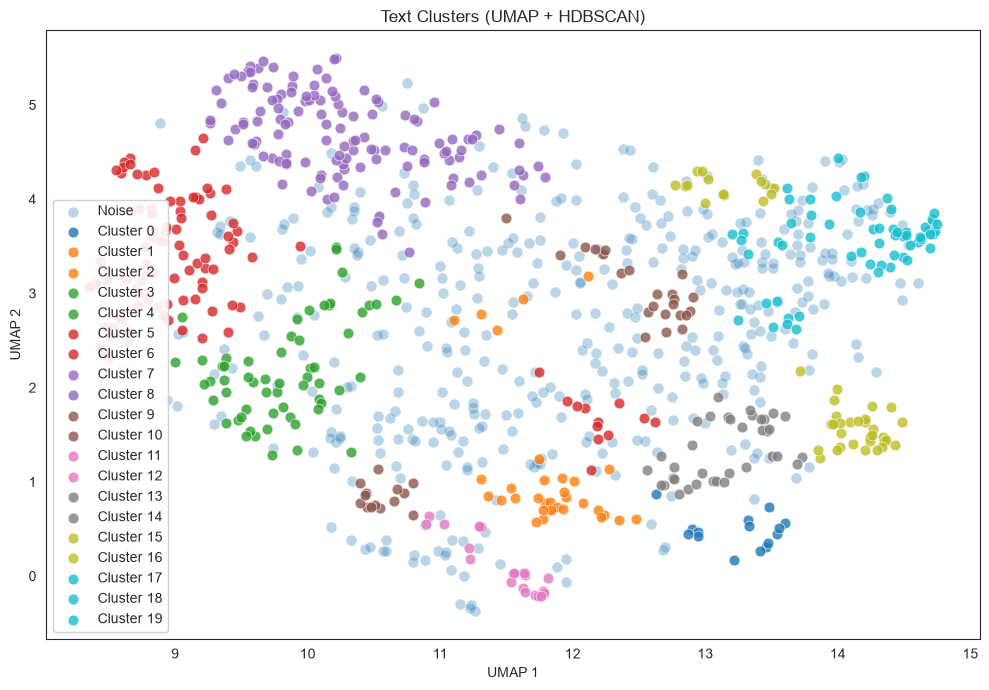

In [94]:
#code ref: https://agentbus.sh/posts/how-to-build-a-text-clustering-pipeline-with-embeddings-and-hdbscan/
# Reduce to 2D for plotting
reducer_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42)
coords = reducer_2d.fit_transform(embeddings)

# Plot
fig, ax = plt.subplots(figsize=(10, 7))

unique_labels = set(labels)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))
color_map = {label: colors[i] for i, label in enumerate(sorted(unique_labels))}

for label in sorted(unique_labels):
    mask = np.array(labels) == label
    name = "Noise" if label == -1 else f"Cluster {label}"
    alpha = 0.3 if label == -1 else 0.8
    ax.scatter(
        coords[mask, 0],
        coords[mask, 1],
        c=[color_map[label]],
        label=name,
        alpha=alpha,
        s=60,
        edgecolors="white",
        linewidth=0.5,
    )

ax.legend(loc="best", framealpha=0.9)
ax.set_title("Text Clusters (UMAP + HDBSCAN)")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
plt.tight_layout()
plt.savefig("clusters.png", dpi=150)
plt.show()



In [95]:
#https://maartengr.github.io/BERTopic/getting_started/topicsperclass/topicsperclass.html

classes = df["artist"]
topics_per_class = topic_model.topics_per_class(docs, classes=classes)
topic_model.visualize_topics_per_class(topics_per_class, top_n_topics=10)

# Latent Dirichlet Allocation (LDA) Topic Modelling

In [22]:
def lemmatize(tokens):
    doc = nlp(" ".join(tokens))
    return [token.lemma_ for token in doc]

df['lemmas'] = df['tokens_spacy'].apply(lemmatize)

In [23]:
# Create dictionary and corpus
id2word = corpora.Dictionary(df['lemmas'])
texts = df['lemmas']
corpus = [id2word.doc2bow(text) for text in texts]

In [24]:
lda_model = gensim.models.ldamodel.LdaModel(corpus=corpus,
                                            id2word=id2word,
                                            num_topics=20, 
                                            random_state=100,
                                            update_every=1,
                                            chunksize=100,
                                            passes=10,
                                            alpha='auto',
                                            per_word_topics=True)

In [ ]:
#| code-summary: 'Run the LDiA flow, condensed from Lab 6'
k_topics_ldia = 14 # MODIFY: vs. BERTopic K topics, equalize or optimize each?

# Topic modelling
X_bow = model.vectorizer_model.transform(docs) #BERTopic
ldia_model = LatentDirichletAllocation(n_components=k_topics_ldia)
ldia_model.fit_transform(X_bow)

# Data wrangling to view top terms per topic
ldia_topics = ldia_model.components_
ldia_topics_norm = ldia_topics / ldia_topics.sum(axis=1)[:, None]
ldia_topics_i = [f'topic_{i}' for i in range(ldia_model.n_components)]
ldia_terms = topic_model.vectorizer_model.get_feature_names_out()
df_ldia_topics_topterms = create_df_rows_topcols(ldia_topics_norm, rows_i=ldia_topics_i, cols_i=ldia_terms, col_type='term', topcol_n=topn)
df_ldia_topics_topterms

In [25]:
# Print the topics
topics = lda_model.print_topics(num_words=8)
for topic in topics:
    print(topic)

(0, '0.058*"stay" + 0.028*"rest" + 0.020*"clean" + 0.020*"fly" + 0.018*"dirty" + 0.018*"see" + 0.018*"life" + 0.017*"real"')
(1, '0.031*"river" + 0.018*"gamble" + 0.008*"medicine" + 0.003*"closing" + 0.000*"deliver" + 0.000*"seems" + 0.000*"insecure" + 0.000*"tend"')
(2, '0.234*"bitch" + 0.101*"nigga" + 0.070*"pussy" + 0.060*"niggas" + 0.039*"fuck" + 0.035*"wet" + 0.026*"wrist" + 0.024*"pull"')
(3, '0.111*"wanna" + 0.049*"night" + 0.046*"please" + 0.039*"watch" + 0.038*"head" + 0.030*"run" + 0.026*"maybe" + 0.024*"baby"')
(4, '0.027*"never" + 0.025*"see" + 0.023*"ghost" + 0.018*"would" + 0.017*"think" + 0.017*"hold" + 0.017*"seem" + 0.016*"come"')
(5, '0.176*"fuck" + 0.046*"smoke" + 0.040*"lean" + 0.033*"get" + 0.032*"shawty" + 0.030*"give" + 0.030*"man" + 0.025*"bitch"')
(6, '0.079*"get" + 0.037*"fuck" + 0.028*"shit" + 0.022*"know" + 0.020*"gon" + 0.018*"dick" + 0.017*"wanna" + 0.015*"cause"')
(7, '0.075*"truth" + 0.060*"first" + 0.038*"waste" + 0.019*"patience" + 0.012*"stretch" + 0.

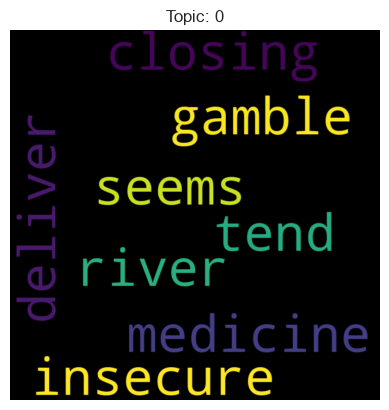

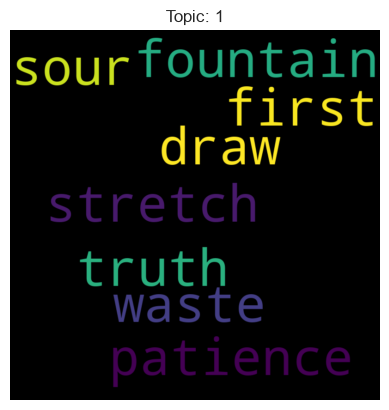

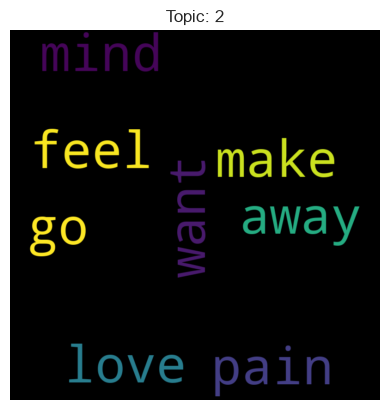

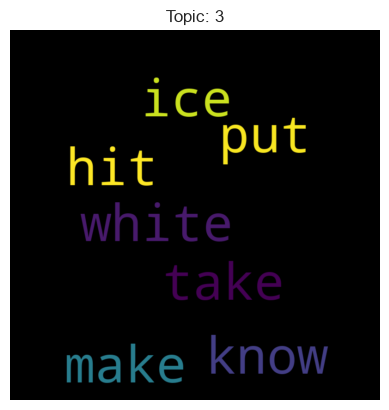

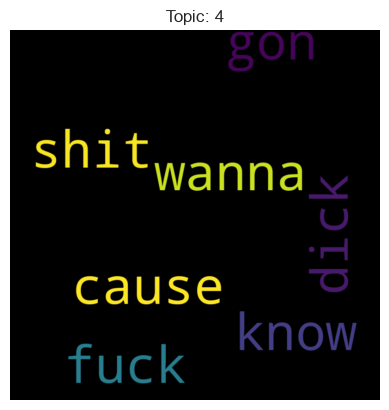

In [91]:
for topic_id, topic in enumerate(lda_model.print_topics(num_topics=5, num_words=8)):
    topic_words = " ".join([word.split("*")[1].strip() for word in topic[1].split(" + ")])
    wordcloud = WordCloud(width=800, height=800, random_state=21, max_font_size=110).generate(topic_words)
    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Topic: {}".format(topic_id))
    plt.show()

### Coherency Scores

In [27]:
# Compute coherence score
coherence_model_lda = CoherenceModel(model=lda_model, texts=df['lemmas'], dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
print('\nCoherence Score: ', coherence_lda)


Coherence Score:  0.3553915710827804


### Diversity Scores

In [85]:
#| code-summary: 'Define evaluation functions to measure coherence and diversity'
#Taken from lab, augmented for dictionary 
dict_diversity = {}
def get_diversity_octis(topics, name, topn=10, dict=dict_diversity):
    '''Calculate topic diversity. Code ref: https://github.com/MIND-Lab/OCTIS.'''
    unique_words = set()
    for topic in topics:
        unique_words = unique_words.union(set(topic[:topn]))
    diversity_score = len(unique_words) / (topn * len(topics))
    dict[name] = diversity_score
    return diversity_score

## Individual Artist LDA 

(0, '0.022*"one" + 0.019*"ice" + 0.018*"life" + 0.016*"dirty" + 0.016*"stay" + 0.015*"know" + 0.013*"need" + 0.013*"something" + 0.011*"get" + 0.011*"clean"')
(1, '0.000*"go" + 0.000*"get" + 0.000*"know" + 0.000*"see" + 0.000*"come" + 0.000*"area" + 0.000*"tell" + 0.000*"want" + 0.000*"alone" + 0.000*"gang"')
(2, '0.079*"side" + 0.024*"motion" + 0.019*"trap" + 0.018*"afterlife" + 0.018*"to" + 0.014*"bitch" + 0.010*"american" + 0.010*"lil" + 0.008*"say" + 0.007*"dab"')
(3, '0.035*"win" + 0.029*"never" + 0.025*"please" + 0.020*"moment" + 0.018*"let" + 0.017*"could" + 0.017*"take" + 0.016*"drama" + 0.015*"world" + 0.015*"hold"')
(4, '0.020*"feel" + 0.019*"away" + 0.019*"well" + 0.018*"get" + 0.018*"see" + 0.013*"one" + 0.012*"play" + 0.012*"give" + 0.012*"make" + 0.011*"come"')
(5, '0.034*"give" + 0.031*"fuck" + 0.015*"stick" + 0.015*"match" + 0.014*"fifty" + 0.014*"sack" + 0.012*"sock" + 0.006*"box" + 0.004*"sbe" + 0.003*"buck"')
(6, '0.036*"get" + 0.025*"love" + 0.021*"know" + 0.019*"st

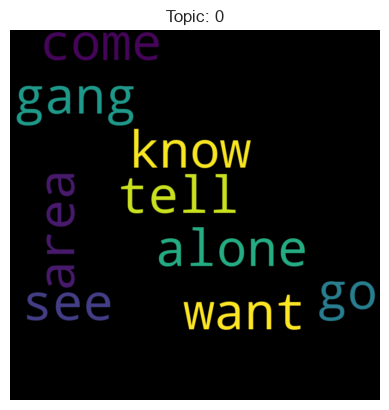

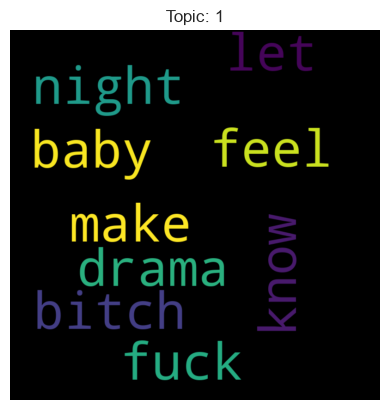

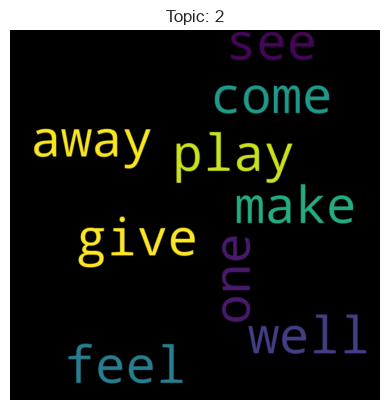

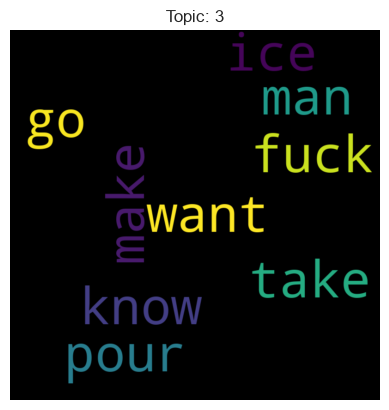

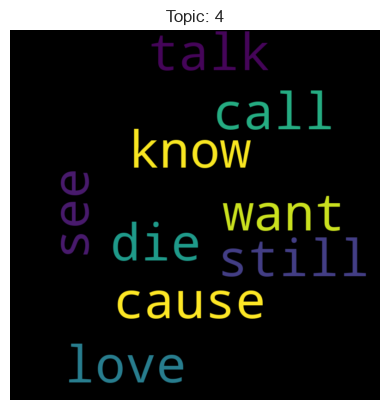


Coherence Score Bladee:  0.36080157057036977


In [ ]:
# bladee
# Create dictionary and corpus
id2word = corpora.Dictionary(df['lemmas'])
texts_b = df.loc[df["artist"] == "bladee", "lemmas"].tolist()
corpus_b = [id2word.doc2bow(text) for text in texts_b]
lda_model_b = gensim.models.ldamodel.LdaModel(corpus=corpus_b,
                                            id2word=id2word,
                                            num_topics=15, 
                                            random_state=100,
                                            update_every=1,
                                            chunksize=100,
                                            passes=10,
                                            alpha='auto',
                                            per_word_topics=True)

# Print the topics
topics_b = lda_model_b.print_topics(num_words=10)
for topic in topics_b:
    print(topic)

get_diversity_octis(topics_b, "bladee")

for topic_id, topic in enumerate(lda_model_b.print_topics(num_topics=5, num_words=10)):
    topic_words = " ".join([word.split("*")[1].strip() for word in topic[1].split(" + ")])
    wordcloud = WordCloud(width=800, height=800, random_state=21, max_font_size=110).generate(topic_words)
    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Topic: {}".format(topic_id))
    plt.show()

# Compute coherence score
coherence_model_lda = CoherenceModel(model=lda_model_b, texts=texts_b, dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
coherency_dict["Bladee Coherency"] = coherence_lda
print('\nCoherence Score Bladee: ', coherence_lda)

(0, '0.051*"low" + 0.031*"lay" + 0.030*"yayo" + 0.023*"top" + 0.019*"way" + 0.017*"sky" + 0.013*"ice" + 0.012*"pop" + 0.012*"burn" + 0.011*"turn"')
(1, '0.029*"famous" + 0.023*"dubai" + 0.020*"cup" + 0.014*"bloody" + 0.014*"knot" + 0.012*"overseas" + 0.010*"wrap" + 0.008*"step" + 0.006*"weirder" + 0.004*"sew"')
(2, '0.033*"blowin" + 0.031*"rollin" + 0.027*"keep" + 0.024*"fire" + 0.017*"around" + 0.016*"stay" + 0.014*"kush" + 0.014*"high" + 0.014*"life" + 0.013*"cause"')
(3, '0.035*"hurt" + 0.029*"flexin" + 0.022*"ice" + 0.022*"float" + 0.021*"waste" + 0.017*"make" + 0.016*"flex" + 0.011*"line" + 0.010*"show" + 0.009*"seem"')
(4, '0.016*"snowman" + 0.014*"travis" + 0.012*"almost" + 0.011*"buy" + 0.010*"hell" + 0.009*"drug" + 0.008*"standin" + 0.008*"benz" + 0.008*"creep" + 0.007*"kill"')
(5, '0.036*"bitch" + 0.029*"fuck" + 0.026*"get" + 0.015*"lean" + 0.014*"shit" + 0.014*"night" + 0.012*"back" + 0.011*"boy" + 0.010*"gucci" + 0.010*"club"')
(6, '0.042*"get" + 0.020*"know" + 0.018*"shawt

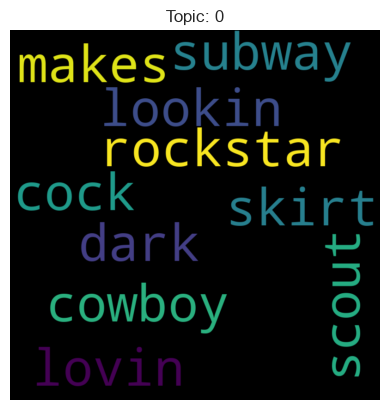

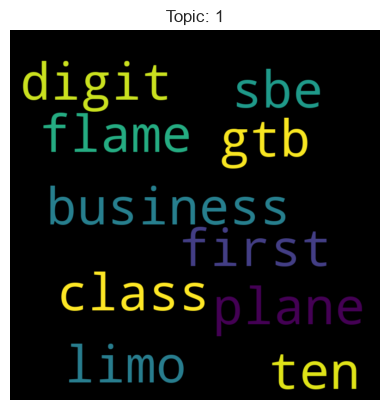

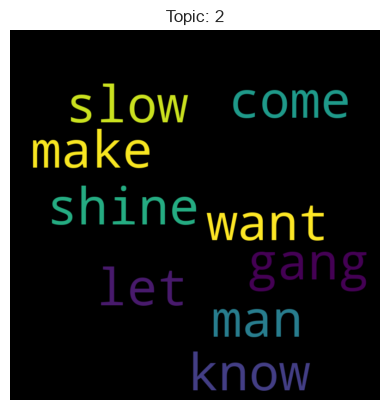

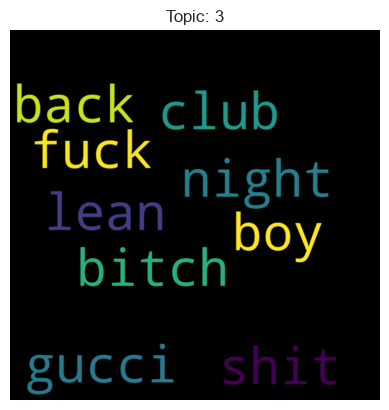

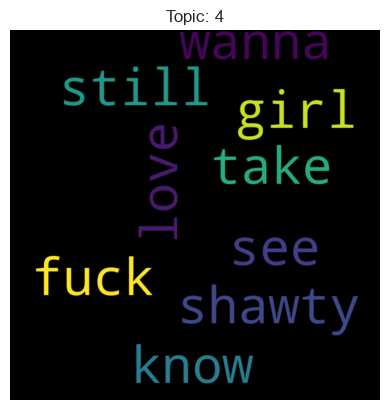


Coherence Score Yung Lean:  0.3761915422093586


In [ ]:
#yung lean
# Create dictionary and corpus
id2word = corpora.Dictionary(df['lemmas'])
texts_yl = df.loc[df["artist"] == "yung lean", "lemmas"].tolist()
corpus_yl = [id2word.doc2bow(text) for text in texts_yl]
lda_model_yl = gensim.models.ldamodel.LdaModel(corpus=corpus_yl,
                                            id2word=id2word,
                                            num_topics=15, 
                                            random_state=100,
                                            update_every=1,
                                            chunksize=100,
                                            passes=10,
                                            alpha='auto',
                                            per_word_topics=True)

# Print the topics
topics_yl = lda_model_yl.print_topics(num_words=10)
for topic in topics_yl:
    print(topic)

get_diversity_octis(topics_yl, "yung lean")

for topic_id, topic in enumerate(lda_model_yl.print_topics(num_topics=5, num_words=10)):
    topic_words = " ".join([word.split("*")[1].strip() for word in topic[1].split(" + ")])
    wordcloud = WordCloud(width=800, height=800, random_state=21, max_font_size=110).generate(topic_words)
    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Topic: {}".format(topic_id))
    plt.show()

# Compute coherence score
coherence_model_lda = CoherenceModel(model=lda_model_yl, texts=texts_yl, dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
coherency_dict["Yung Lean Coherency"] = coherence_lda
print('\nCoherence Score Yung Lean: ', coherence_lda)

(0, '0.050*"one" + 0.030*"walk" + 0.029*"know" + 0.021*"bih" + 0.020*"dis" + 0.014*"black" + 0.014*"smile" + 0.014*"without" + 0.014*"worth" + 0.012*"maybe"')
(1, '0.016*"do" + 0.013*"anyway" + 0.012*"god" + 0.010*"geeke" + 0.010*"slug" + 0.010*"thuggin" + 0.009*"weekend" + 0.008*"flame" + 0.008*"truly" + 0.007*"bet"')
(2, '0.102*"night" + 0.071*"twisted" + 0.049*"twist" + 0.034*"bust" + 0.022*"get" + 0.020*"life" + 0.018*"wild" + 0.010*"bean" + 0.010*"focus" + 0.010*"lose"')
(3, '0.045*"know" + 0.039*"time" + 0.027*"wanna" + 0.023*"line" + 0.021*"girl" + 0.021*"right" + 0.019*"get" + 0.018*"thing" + 0.015*"ill" + 0.015*"see"')
(4, '0.024*"heart" + 0.018*"wanna" + 0.018*"tell" + 0.017*"away" + 0.015*"die" + 0.015*"gettin" + 0.013*"get" + 0.013*"blow" + 0.013*"still" + 0.012*"would"')
(5, '0.072*"cocaine" + 0.049*"sell" + 0.028*"fuck" + 0.022*"gon" + 0.021*"get" + 0.015*"give" + 0.013*"bitch" + 0.012*"drug" + 0.012*"numb" + 0.012*"plug"')
(6, '0.043*"get" + 0.034*"bitch" + 0.029*"fuck" 

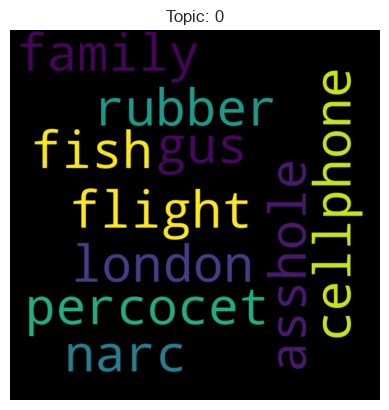

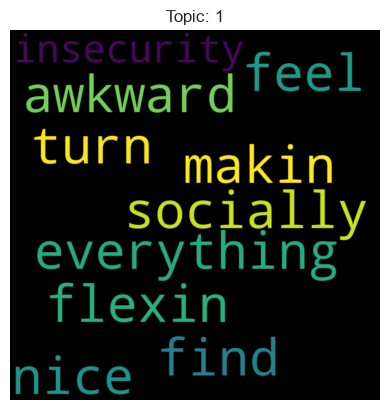

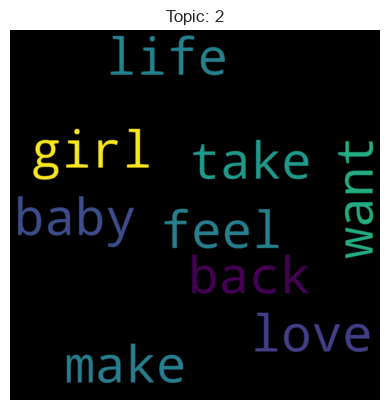

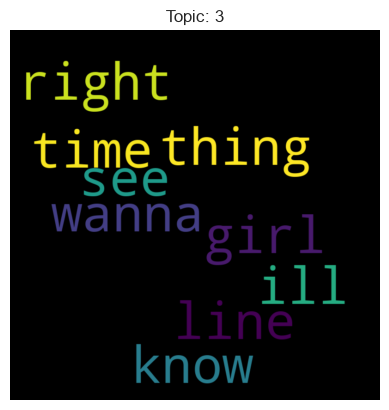

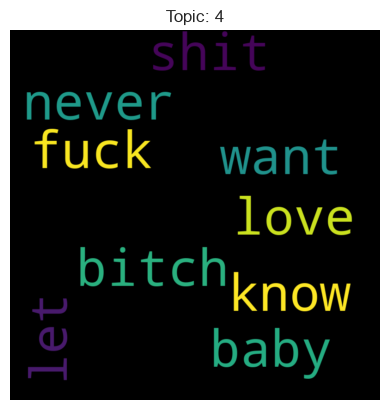


Coherence Score Lil peep:  0.358948859621666


In [ ]:
# lil peep
# Create dictionary and corpus
id2word = corpora.Dictionary(df['lemmas'])
texts_lp = df.loc[df["artist"] == "lil peep", "lemmas"].tolist()
corpus_lp = [id2word.doc2bow(text) for text in texts_lp]
lda_model_lp = gensim.models.ldamodel.LdaModel(corpus=corpus_lp,
                                            id2word=id2word,
                                            num_topics=15, 
                                            random_state=100,
                                            update_every=1,
                                            chunksize=100,
                                            passes=10,
                                            alpha='auto',
                                            per_word_topics=True)

# Print the topics
topics_lp = lda_model_lp.print_topics(num_words=10)
for topic in topics_lp:
    print(topic)

get_diversity_octis(topics_lp, "lil peep")

for topic_id, topic in enumerate(lda_model_lp.print_topics(num_topics=5, num_words=10)):
    topic_words = " ".join([word.split("*")[1].strip() for word in topic[1].split(" + ")])
    wordcloud = WordCloud(width=800, height=800, random_state=21, max_font_size=110).generate(topic_words)
    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Topic: {}".format(topic_id))
    plt.show()

# Compute coherence score
coherence_model_lda = CoherenceModel(model=lda_model_lp, texts=texts_lp, dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
coherency_dict["Lil Peep Coherency"] = coherence_lda
print('\nCoherence Score Lil peep: ', coherence_lda)

(0, '0.033*"option" + 0.018*"toxic" + 0.018*"help" + 0.018*"hot" + 0.017*"yeh" + 0.016*"commit" + 0.016*"profit" + 0.015*"pastor" + 0.014*"inna" + 0.014*"sky"')
(1, '0.047*"head" + 0.039*"run" + 0.030*"bleed" + 0.027*"damn" + 0.025*"thought" + 0.022*"enemy" + 0.014*"different" + 0.012*"jugg" + 0.012*"walk" + 0.011*"slip"')
(2, '0.128*"wet" + 0.071*"arm" + 0.068*"around" + 0.028*"want" + 0.027*"girl" + 0.026*"wrist" + 0.017*"pack" + 0.016*"boof" + 0.014*"diamond" + 0.014*"water"')
(3, '0.058*"moonlight" + 0.049*"right" + 0.033*"trippin" + 0.033*"shawty" + 0.030*"good" + 0.030*"get" + 0.030*"bad" + 0.030*"nigga" + 0.030*"pussy" + 0.030*"mind"')
(4, '0.021*"slip" + 0.021*"break" + 0.017*"heart" + 0.016*"forget" + 0.014*"uoy" + 0.014*"never" + 0.013*"dna" + 0.013*"bleed" + 0.013*"blast" + 0.013*"ill"')
(5, '0.072*"fuck" + 0.049*"shit" + 0.044*"god" + 0.020*"spouse" + 0.016*"stand" + 0.012*"whip" + 0.010*"every" + 0.009*"understand" + 0.009*"hop" + 0.009*"fucking"')
(6, '0.050*"bitch" + 0.0

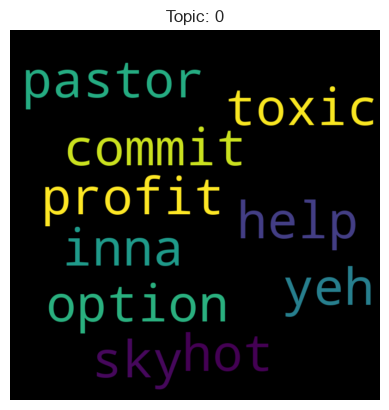

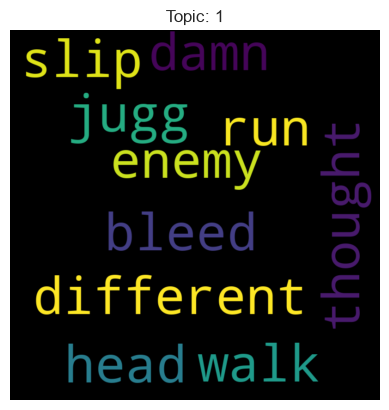

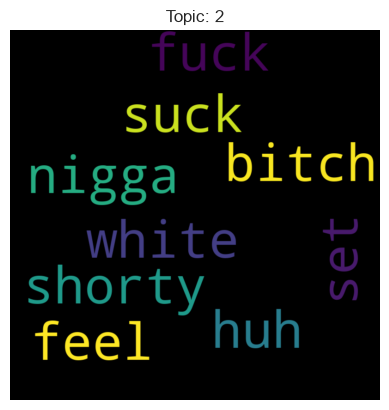

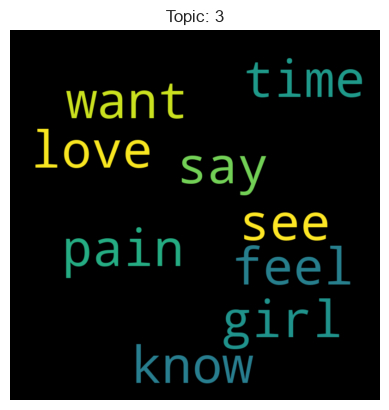

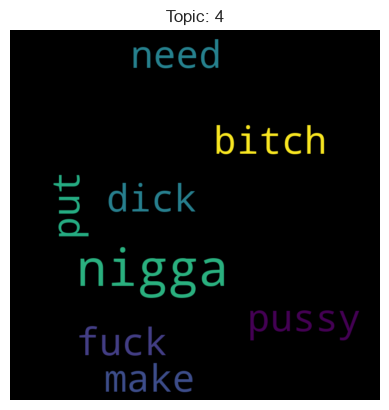


Coherence Score XXXTentacion:  0.3764405956839339


In [ ]:
#xxx
# Create dictionary and corpus
id2word = corpora.Dictionary(df['lemmas'])
texts_xxx = df.loc[df["artist"] == "xxxtentacion", "lemmas"].tolist()
corpus_xxx = [id2word.doc2bow(text) for text in texts_xxx]
lda_model_xxx = gensim.models.ldamodel.LdaModel(corpus=corpus_xxx,
                                            id2word=id2word,
                                            num_topics=15, 
                                            random_state=100,
                                            update_every=1,
                                            chunksize=100,
                                            passes=10,
                                            alpha='auto',
                                            per_word_topics=True)

# Print the topics
topics_xxx = lda_model_xxx.print_topics(num_words=10)
for topic in topics_xxx:
    print(topic)
    
get_diversity_octis(topics_xxx, "xxxtentacion")

for topic_id, topic in enumerate(lda_model_xxx.print_topics(num_topics=5, num_words=10)):
    topic_words = " ".join([word.split("*")[1].strip() for word in topic[1].split(" + ")])
    wordcloud = WordCloud(width=800, height=800, random_state=21, max_font_size=110).generate(topic_words)
    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Topic: {}".format(topic_id))
    plt.show()

# Compute coherence score
coherence_model_lda = CoherenceModel(model=lda_model_xxx, texts=texts_xxx, dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
coherency_dict["XXXTentacion Coherency"] = coherence_lda
print('\nCoherence Score XXXTentacion: ', coherence_lda)

In [29]:
#| code-summary: 'Configure and train BERTopic with (mostly) default settings'
#| code-fold: false
docs = df['text'].tolist() # keep only 'text'
len(docs)
# Configure
topic_model = BERTopic(             # (defaults)
    # 3. Clustering
    min_topic_size = 10,            # (10) important! equivalent to HDBSCAN min_cluster_size
    
    # 4. Tokenizer/Vectorizer       # (CountVectorizer())
    vectorizer_model = CountVectorizer(stop_words="english", min_df=2),
    
    # 5. cTF-IDF -> Topic-Terms
    top_n_words = 10,               # (10) increase for more detailed topic descriptions
    nr_topics = None,               # (None) heed warnings!
)
# Train
topics, probs = topic_model.fit_transform(docs) # topics, probs may get updated later so we later use "live" attributes instead!
print(f'Initial number of topics (incl. -1): {topic_model.get_topic_info().shape[0]}')
print(f'Initial vocabulary size: {len(topic_model.vectorizer_model.get_feature_names_out())}\n')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8008.11it/s]


Initial number of topics (incl. -1): 12
Initial vocabulary size: 4720



## Topic Embeddings

By default, the clustering step (#3) uses HDBSCAN to cluster documents together into topics. Each topic can then be represented as a combination of its member documents' embeddings in the original 384-dimension space of its `SentenceTransformer` model from step #1.

▶️ Display the model's`topic_embeddings_` attribute to view the post-clustering topic embeddings.<br>
👁️ Notice the meaning of the dimensions and the **dense** representation.<br>

📚 BERTopic: 1️⃣ [Embeddings](https://maartengr.github.io/BERTopic/getting_started/embeddings/embeddings.html) ➜  2️⃣ [Dimensionality Reduction](https://maartengr.github.io/BERTopic/getting_started/dim_reduction/dim_reduction.html) ➜ 3️⃣ [Clustering](https://maartengr.github.io/BERTopic/getting_started/clustering/clustering.html) <br>
⚠️ Check `topic_model.embedding_model.embedding_model.max_seq_length`. The embedding model truncates each document after this number of tokens! One solution could be to split long documents IF that is reasonable for your task.<br>
📝 These embeddings consider word sequence and context using self-attention, hence the "Transformers" in its name!

In [30]:
#| code-summary: 'Display topic embeddings as output of Step #3: Clustering'
display(topic_model.topic_embeddings_.shape)
pd.DataFrame(
    topic_model.topic_embeddings_,
    index = topic_model.get_topic_info()['Topic'],
).head()

(12, 384)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,299,300,301,302,303,304,305,306,307,308,309,310,311,312,313,314,315,316,317,318,319,320,321,322,323,324,325,326,327,328,329,330,331,332,333,334,335,336,337,338,339,340,341,342,343,344,345,346,347,348,349,350,351,352,353,354,355,356,357,358,359,360,361,362,363,364,365,366,367,368,369,370,371,372,373,374,375,376,377,378,379,380,381,382,383
Topic,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
-1,-0.052939,-0.052385,0.024028,-0.021181,0.022794,0.005733,0.111776,-0.000537,0.063161,-0.029609,-0.024015,-0.048748,0.026462,-0.008400,-0.036340,0.051059,0.038480,0.030770,-0.076652,0.047922,-0.008288,0.033612,-0.019693,0.015439,-0.080189,0.054622,-0.036786,-0.000844,-0.072933,-0.004249,0.024478,0.037300,-0.022454,-0.001803,0.028038,0.022093,-0.046388,0.022433,0.020671,0.001116,0.026740,-0.012494,0.009288,-0.003588,-0.013044,0.002189,-0.027677,-0.017613,0.034416,-0.065259,-0.038397,-0.027638,0.035954,0.058336,-0.031059,0.016451,0.041049,0.048819,0.015688,0.008578,-0.027942,-0.013866,0.030047,-0.021793,0.036129,0.003855,-0.010712,0.018299,-0.033519,0.066087,-0.006933,-0.004152,-0.034657,0.026397,-0.035960,0.067450,-0.006857,-0.051435,-0.014457,0.011473,0.013331,0.002548,0.009833,-0.033819,-0.078943,-0.042205,-0.011166,0.010872,0.039515,-0.020470,0.014375,0.007164,-0.030667,-0.011423,0.044054,-0.060917,-0.053031,0.019612,-0.060522,0.065727,0.060004,-0.025281,0.024498,-0.004693,0.051764,0.004511,0.019048,0.043646,0.002294,0.004384,-0.004490,-0.004464,-0.016723,-0.010099,0.016266,-0.019730,-0.004608,-0.006540,0.012308,0.029618,-0.020244,0.003760,-0.044667,0.044117,-0.025672,-0.037039,-0.026248,3.225197e-33,0.037966,0.008239,-0.011385,0.034369,0.079705,-0.011974,-0.057558,0.019490,-0.050046,0.018097,-0.034461,-0.032277,-0.051676,0.022985,0.016032,-0.047250,0.002064,-0.085168,0.003079,0.028257,-0.034912,0.030619,0.012245,-0.028224,-0.049448,-0.001758,-0.032997,-0.004466,0.001644,0.016405,-0.026970,0.018627,0.042975,-0.024839,-0.053196,-0.017036,0.019251,0.001081,-0.049717,-0.047819,-0.030918,0.039082,-0.031717,0.016744,-0.018284,0.054237,-0.049174,0.045701,-0.016010,0.023191,-0.013082,-0.000719,-0.005711,-0.006576,0.004098,-0.004835,-0.028298,0.030857,0.061405,0.012707,0.022507,-0.035587,0.025970,-0.030967,0.020471,-0.028279,0.012225,-0.047618,0.016775,0.010507,-0.039200,0.001297,0.010419,0.051892,0.048879,-0.012869,0.038451,-0.038277,-0.024480,0.021778,0.037386,-0.003708,-0.047166,0.011989,0.046317,-0.061443,0.034104,-0.057986,-0.012123,-0.008511,-0.096775,0.016533,0.049282,-0.081504,-0.047790,-2.824146e-33,0.058293,0.041882,0.071112,0.061100,0.043

## Topic-Term Matrix

Part of BERTopic's magic is how it uses semantic/contextual embeddings to cluster documents into topics and then separately uses the **human-interpretable** word-based TF-IDF to represent each topic. It does this by:

1. Joining all documents of a topic together into **one long document**.
2. Calculating this **class-based** "c"-TF-IDF vector for each topic.

▶️ Display the model's `c_tf_idf` attribute to view the Topic-Term Matrix as c-TF-IDF weights.<br>
👁️ Inspect:

- Notice the meaning of the dimensions and the **sparse** representation.
- Each topic vector does not sum up to 1 as these are not probabilities!

📚 BERTopic: 4️⃣ [Vectorizers](https://maartengr.github.io/BERTopic/getting_started/vectorizers/vectorizers.html) ➜ 5️⃣ [c-TF-IDF](https://maartengr.github.io/BERTopic/getting_started/ctfidf/ctfidf.html)<br>

In [31]:
#| code-summary: 'Display Topic-Term Matrix of cTF-IDF weights as output of step #5'
display(topic_model.c_tf_idf_.shape)
pd.DataFrame(
    topic_model.c_tf_idf_.toarray(), # can limit [:n]
    index = topic_model.get_topic_info()['Topic'], # can limit [:n]
    columns = topic_model.vectorizer_model.get_feature_names_out(),
).head()

(12, 4720)

03        10       100       10k        11        12        13  \
Topic                                                                         
-1     0.000147  0.001862  0.000803  0.000111  0.001721  0.001241  0.001192   
 0     0.000691  0.001464  0.001624  0.000525  0.000812  0.001065  0.000844   
 1     0.000000  0.001031  0.001429  0.000277  0.000000  0.001406  0.000297   
 2     0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
 3     0.000000  0.001023  0.000000  0.000000  0.000000  0.000000  0.000000   

             14        15        16        17        18        19        1s  \
Topic                                                                         
-1     0.000723  0.000550  0.003309  0.001084  0.001851  0.001168  0.000350   
 0     0.001421  0.000324  0.001148  0.000284  0.001285  0.001654  0.003307   
 1     0.000000  0.000000  0.000000  0.000300  0.000271  0.000000  0.000000   
 2     0.001132  0.000000  0.000000  0.002264  0.000000  0.000000  0.000000   
 3     0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   

             20      2001      2013      2015      2016      2019      2020  \
Topic                                                                         
-1     0.002299  0.000147  0.000424  0.001235  0.000550  0.000537  0.000671   
 0     0.001233  0.000691  0.000000  0.000000  0.000324  0.000000  0.000000   
 1     0.001042  0.000000  0.000352  0.000000  0.000000  0.000000  0.000334   
 2     0.000982  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
 3     0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   

             21        22        23        24       247        25        26  \
Topic                                                                         
-1     0.000853  0.000694  0.002318  0.001180  0.000000  0.002001  0.003364   
 0     0.000863  0.001638  0.000521  0.001391  0.000363  0.001049  0.000481   
 1     0.000608  0.000288  0.000000  0.000000  0.000383  0.000000  0.000000   
 2     0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
 3     0.000000  0.004580  0.000000  0.000000  0.000000  0.000000  0.000000   

             27        28        29        2s        30        31       360  \
Topic                                                                         
-1     0.000550  0.000904  0.000154  0.000424  0.001063  0.000751  0.000424   
 0     0.000324  0.000305  0.000363  0.000000  0.003510  0.001181  0.000334   
 1     0.000000  0.000000  0.000000  0.000352  0.001324  0.000000  0.000000   
 2     0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
 3     0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   

             38        3d        40       400       40s        44        45  \
Topic                                                                         
-1     0.000000  0.000250  0.001389  0.000147  0.000154  0.000141  0.000154   
 0     0.000000  0.002362  0.000273  0.000000  0.000363  0.000334  0.000000   
 1     0.000383  0.000000  0.001153  0.000365  0.000000  0.000705  0.000383   
 2     0.000000  0.000000  0.000000  0.001377  0.000000  0.000000  0.000000   
 3     0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   

             4s        50        5s        60   7eleven        80       80s  \
Topic                                                                         
-1     0.000154  0.000472  0.000293  0.000000  0.000211  0.000154  0.000236   
 0     0.000363  0.000000  0.000000  0.000346  0.000000  0.000000  0.002505   
 1     0.000000  0.002645  0.000000  0.000730  0.000000  0.000383  0.000000   
 2     0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
 3     0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   

            925        95     aaall       aap  abandoned       abc      able  \
Topic                                                  

In [32]:
#| code-summary: 'Display a few per-topic row term sums'
topic_model.c_tf_idf_[0:10].sum(axis=1)

matrix([[4.38696759],
        [4.58448867],
        [4.40405994],
        [4.76248022],
        [4.09761488],
        [4.75125365],
        [4.2689624 ],
        [4.66913246],
        [4.56788548],
        [4.27917817]])

## ✈️ Topics Summary

▶️ The `get_topic_info()` method is the best way to get a high-level summary of the topics that BERTopic generated.<br>
👁️ Inspect:

- For topic 0, find one of its **representative terms** in the topic 0 row in the **topic-term matrix** above. It should have a relatively high value.
- Are there representative words that do not help to interpret topics such as very common or rare words? Note any **need for vocabulary normalization** when we re-vectorize below.
  
🔄 View more top topics with `.head(top_n)`

📚 BERTopic [get_topic_info()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.get_topic_info), [set_topic_labels()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.set_topic_labels), [update_topics()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.update_topics)<br>
📝 Notice **topic -1**. HDBSCAN automatically identifies outliers which can not be clustered with any topic. BERTopic provides some strategies for [Outlier reduction](https://maartengr.github.io/BERTopic/getting_started/outlier_reduction/outlier_reduction.html).

In [33]:
#| code-summary: 'Display the topic summary by document count order'
#| code-fold: false
display(topic_model.get_topic_info().shape) #names by 4 most common words 
topic_model.get_topic_info().iloc[:, :-1].head(10) # MODIFY: to see more/less topics (omit Representative_Docs)

(12, 5)

,Topic,Count,Name,Representation
0,-1,416,-1_im_dont_know_like,"[im, dont, know, like, got, just, yeah, wanna, fuck, love]"
1,0,139,0_im_like_got_lean,"[im, like, got, lean, shawty, fuck, dont, bitch, money, know]"
2,1,126,1_bitch_fuck_nigga_like,"[bitch, fuck, nigga, like, im, shit, uh, huh, dick, pussy]"
3,2,60,2_feel_mind_im_like,"[feel, mind, im, like, dont, know, open, world, away, wrist]"
4,3,51,3_youre_dont_wanna_know,"[youre, dont, wanna, know, time, wrong, promise, im, love, baby]"
5,4,46,4_im_like_gang_drain,"[im, like, gang, drain, dont, life, need, know, clean, fuck]"
6,5,27,5_dont_love_like_im,"[dont, love, like, im, girl, just, real, know, got, feel]"
7,6,24,6_think_life_feel_beautiful,"[think, life, feel, beautiful, im, know, dont, youre, pain, fucking]"
8,7,22,7_ice_im_flames_man,"[ice, im, flames, man, froze, away, sky, like, 10k, dont]"
9,8,20,8_flex_love_acid_thug,"[flex, love, acid, thug, 7eleven, im, dont, baby, like, yeah]"


## 🔎 Per-Topic Word Score
▶️ Below are two ways to analyze a specific topic(s)'s top word scores for more in-depth analysis: bar charts and raw scores.<br>
👁️ Do the word score distributions help make sense of some of the most distinctive/relevant topics? <br>
🔄 Enter the topic indices that you are interested in analyzing.

📚 BERTopic [Visualize Terms](https://maartengr.github.io/BERTopic/getting_started/visualization/visualize_terms.html), [visualize_barchart()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.visualize_barchart), [get_topic()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.get_topic)

In [34]:
#| code-summary: 'Visualize a list of topics by their word scores'
topic_model.visualize_barchart( # (defaults)
    topics = [0, 1, 2],         # (None), list overrides top_n_topics
    top_n_topics = 8,           # (8)
    n_words = 10,               # (5)
    autoscale = True,           # (False), may not see all words otherwise!
)

In [35]:
#| code-summary: 'Analyze one topic by its raw word scores'
topic_model.get_topic(0)

[('im', np.float64(0.044437859303640775)),
 ('like', np.float64(0.03770602713842987)),
 ('got', np.float64(0.03692975706724654)),
 ('lean', np.float64(0.03313629014082916)),
 ('shawty', np.float64(0.030867732680176226)),
 ('fuck', np.float64(0.029314851691633143)),
 ('dont', np.float64(0.028494522542388667)),
 ('bitch', np.float64(0.027754923796095305)),
 ('money', np.float64(0.025539194184314305)),
 ('know', np.float64(0.023244111568566737))]

## Change Topic Representation
We can change which words are used to represent the topic (steps #4-5) by using various tokenization/normalization options that we are already familiar with from Labs 2-3 using `update_topics()` such as:

- Removing stopwords recommended [here](https://maartengr.github.io/BERTopic/getting_started/tips_and_tricks/tips_and_tricks.html#removing-stop-words)
- Lemmatization ← **via our old friend spaCy!**
- N-grams
- Corpus-level vocabulary control: `max_df` (common words), `min_df` (rare words), `max_features`

🔄 Add your options to the `Count_Vectorizer()` configuration.<br>
▶️ Call `update_topics()` with the new vectorizer and include any other changes provided by its parameters.<br>
👁️ Does the vocabulary size change as expected? Does the new representation make the **topic more interpretable?**<br>

📚 scikit-learn [CountVectorizer()](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html), BERTopic [Update Topic Representations](https://maartengr.github.io/BERTopic/getting_started/topicrepresentation/topicrepresentation.html), [update_topics()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.update_topics)<br>
📝 Notes:

- This involves re-calculating the cTF-IDF weights based on the new representation.
- This does NOT change the actual topic clustering from step #3. Modularity! ✨

In [36]:
#| code-summary: 'Change topic label names'
#| code-fold: false
topn = 10 # MODIFY?

vectorizer_model = CountVectorizer(stop_words='english', min_df=2, max_df=0.5) # MODIFY: normalization options
topic_model.update_topics(docs, vectorizer_model=vectorizer_model, top_n_words=topn) # MODIFY: n_gram_range?
print(f'Modified vocabulary size: {len(topic_model.vectorizer_model.get_feature_names_out())}')
topic_model.get_topic_info().iloc[:, :-1].head()

Modified vocabulary size: 4122


,Topic,Count,Name,Representation
0,-1,416,-1_ha_niggas_drama_moonlight,"[ha, niggas, drama, moonlight, lay, scared, december, march, ho, jug]"
1,0,139,0_pour_yung_sbe_designer,"[pour, yung, sbe, designer, sell, bands, bih, sippin, sip, dis]"
2,1,126,1_niggas_suck_pistol_glock,"[niggas, suck, pistol, glock, shorty, yes, flexin, prom, gassed, hood]"
3,2,60,2_grave_minute_rot_magic,"[grave, minute, rot, magic, doors, poison, silence, rainbow, adore, afraid]"
4,3,51,3_aching_nothings_bust_shouldve,"[aching, nothings, bust, shouldve, drowning, mmm, spotlight, dear, fault, crybaby]"


## Change Topic Naming

We can also change how the topics are named.

▶️ We use `set_topic_labels()` to manually assign new topic names. It can also be used with `generate_topic_labels()` to change the name formatting template from `'i_word1_word2_word3_word4'`.<br>
🔄 Update any topic names that would help with later analysis.

📚 BERTopic: [set_topic_labels()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.set_topic_labels), [generate_topic_labels()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.generate_topic_labels) (formatting parameters)

In [37]:
#| code-summary: 'Change topic label names'
#| code-fold: false
#topic_model.set_topic_labels({0: 'Cars', 1: 'Sports', 2: 'Religion'}) # MODIFY: rename to better labels
topic_model.get_topic_info().iloc[:, :-2].head() # check after changes

,Topic,Count,Name
0,-1,416,-1_ha_niggas_drama_moonlight
1,0,139,0_pour_yung_sbe_designer
2,1,126,1_niggas_suck_pistol_glock
3,2,60,2_grave_minute_rot_magic
4,3,51,3_aching_nothings_bust_shouldve


## 🟣 🔵 🟢 Topic-Topic Relationships

Two useful visualizations can be used in conjunction to look for topic-to-topic relationships, including merging candidates.

▶️ The first is `visualize_topics()` where topics can be mapped to 2-dimensions using UMAP.<br>
👁️ Do some/many topics cluster together? Does the clustering make sense to you?<br>
🔄 Try mapping both embeddings and cTF-IDF weights by toggling the `use_ctfidf` parameter.

📚 BERTopic: [Visualize Topics](https://maartengr.github.io/BERTopic/getting_started/visualization/visualize_topics.html), [visualize_topics()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.visualize_topics)

In [38]:
#| code-summary: 'Visualize topics in UMAP 2-dimensional space'
topic_model.visualize_topics( # (defaults)
    use_ctfidf = False,       # (False) map embeddings / True: map cTF-IDF weights
    top_n_topics = None,      # (None) all
    custom_labels = True,     # (False)
)

The second visualization is even more useful to identify clusters of topics by high **cosine similarity**. 

▶️ Run `visualize_heatmap()` to get the idea of topic-to-topic simiarity.<br>
🔄 Modify:

- Recall the `visualize_topics()` 2d plot above to guess an initial `n_clusters` to cluster similar topics. **This is very useful and highly recommended** for analyzing potential topics to merge.
- Try different values of `n_clusters`
- Try both embeddings and cTF-IDF using `use_ctfidf`. Which one exhibits more distinctive clusters?

👁️ Inspect:

- Is it now clear from the similarity clustering which topics are candidates for merging?
- Or do you need to review some actual documents first? → Skip to **BERTopic Documents**.

📚 BERTopic: [Visualize Topics](https://maartengr.github.io/BERTopic/getting_started/visualization/visualize_topics.html), [visualize_heatmap()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.visualize_heatmap)

In [39]:
#| code-summary: "Visualize topic embeddings' cosine similarities and look for clusters of topics"
topic_model.visualize_heatmap( # (defaults)
    use_ctfidf = False,        # (False) map embeddings / True: map cTF-IDF weights
    #n_clusters = 10,           # (None) <- MODIFY: powerful! creates ordered CLUSTERS of similar topics
    top_n_topics = None,       # (None) all
    custom_labels = True,      # (False)
)

# BERTopic Modify Topics
BERTopic provides an informative page on various [Topic Reduction](https://maartengr.github.io/BERTopic/getting_started/topicreduction/topicreduction.html) strategies.

Each modification below should be followed by running:

1. X1: Re-Check Topic Summary
2. And if effective: X2. Re-Check Topic Visualizations

## 🌟 Set `min_topic_size` (Step #3: HDBSCAN clustering)
This is the preferred method: to **rely on the HDBSCAN clustering algorithm** to find your number of topics. This can be used to **both decrease and increase** the number of topics that the clustering provides.

🔄 Check the topic summary to see what topic sizes (under **Count**) are being created, and modify `min_topic_size` accordingly.

- for less topics, try increasing `min_topic_size`
- for more topics, try decreasing `min_topic_size`

▶️ This needs to be done at BERTopic instantiation, i.e., the first cell here under **BERTopic Default Topics**<br>
👁️ Re-check the topic summary and see how the number of topics and their representations changed.<br>

📚 BERTopic: [Topic Reduction](https://maartengr.github.io/BERTopic/getting_started/topicreduction/topicreduction.html), [min_topic_size](https://maartengr.github.io/BERTopic/getting_started/parameter%20tuning/parametertuning.html#min_topic_size)

In [40]:
#| code-summary: 'Re-configure and train BERTopic, modifying `min_topic_size`'
#| code-fold: false

# Configure
topic_model = BERTopic(             # (defaults)
    # 3. Clustering
    min_topic_size = 10,            # (10) important! equivalent to HDBSCAN min_cluster_size
    
    # 4. Tokenizer/Vectorizer       # (CountVectorizer())
    vectorizer_model = CountVectorizer(stop_words="english", min_df=2),
    
    # 5. cTF-IDF -> Topic-Terms
    top_n_words = 10,               # (10) increase for more detailed topic descriptions
    nr_topics = None,               # (None) heed warnings!
)
# Train
topics, probs = topic_model.fit_transform(docs) # topics, probs may get updated later so we later use "live" attributes instead!
print(f'Modified number of topics (incl. -1): {topic_model.get_topic_info().shape[0]}')
print(f'Modified vocabulary size: {len(topic_model.vectorizer_model.get_feature_names_out())}\n')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6594.41it/s]


Modified number of topics (incl. -1): 11
Modified vocabulary size: 4670



## A. Reduce topics automatically (HDBSCAN on cTF-IDF vectors)

▶️ We can re-use HDBSCAN to automatically reduce topics by clustering the cTF-IDF vectors (post step #5).<br>
👁️ Re-check the topic summary and see how the number of topics and their new representations changed.<br>

📚 BERTopic: [Automatic Topic Reduction](https://maartengr.github.io/BERTopic/getting_started/topicreduction/topicreduction.html#automatic-topic-reduction), [reduce_topics(nr_topics='auto')](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.reduce_topics)<br>
📝 Notes:

- This may be a good first option if there are too many initial topics for manual merging
- `nr_topics='auto'` can also specified at BERTopic instantiation

In [41]:
#| code-summary: 'Run HDBSCAN to cluster topics by their cTF-IDF vectors'
#| code-fold: false
topic_model.reduce_topics(docs, nr_topics='auto') # can be run n times until converges
print(f'Modified number of topics (incl. -1): {topic_model.get_topic_info().shape[0]}')

Modified number of topics (incl. -1): 11


## B. Merge known topics (Post-Training on cTF-IDF vectors)

🔄 Create a list (or list of lists) to merge specific topics that you noted from your analysis above.<br>
▶️ Input the list to `merge_topics()`<br>
👁️ Re-check the topic summary and see how the merged topics were combined (check **Count**, **Name**, **Representation**), and all topics re-ordered.<br>

📚 BERTopic: [Manual Topic Reduction](https://maartengr.github.io/BERTopic/getting_started/topicreduction/topicreduction.html#manual-topic-reduction), [merge_topics()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.merge_topics)

In [42]:
#| code-summary: 'Merge topics that you specify'
#| code-fold: false
topics_to_merge = [1, 2] # MODIFY: list (or list of lists), should not re-run as numbers are re-arranged
topic_model.merge_topics(docs, topics_to_merge)
print(f'Modified number of topics (incl. -1): {topic_model.get_topic_info().shape[0]}')

Modified number of topics (incl. -1): 10


## <span style="color: red;">C. Reduce topics to fixed number (Post-Training on cTF-IDF vectors)</span>
🔄 Set a fixed number of topics in the `nr_topics` parameter<br>
▶️ Run `reduce_topics()` with this `nr_topics` number.<br>
👁️ Re-check the topic summary and see how the topics were reduced to the fixed number.<br>

📚 BERTopic: [Topic Reduction after Training](https://maartengr.github.io/BERTopic/getting_started/topicreduction/topicreduction.html#topic-reduction-after-training), [reduce_topics](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.reduce_topics)<br>
⚠️ Warning: `nr_topics` can force K topics post-clustering but is <span style="color: red;">warned against</span> [here](https://maartengr.github.io/BERTopic/getting_started/topicreduction/topicreduction.html) and <span style="color: red;">noted as "tricky"</span> [here](https://maartengr.github.io/BERTopic/getting_started/parameter%20tuning/parametertuning.html#nr_topics).

In [43]:
#| code-summary: 'Reduce topics to a specified number of topics'
#| code-fold: false
nr_topics = 10 # MODIFY: number of topics
topic_model.reduce_topics(docs, nr_topics=nr_topics)
print(f'Modified number of topics (incl. -1): {topic_model.get_topic_info().shape[0]}')

Modified number of topics (incl. -1): 10


## X1. Re-Check Topic Summary
👁️ Check modified topics after each modification step above.<br>
🔄 View more top topics with `.head(top_n)`

📚 BERTopic [get_topic_info()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.get_topic_info)

In [44]:
#| code-summary: 'Display the topic summary by document count order'
display(topic_model.get_topic_info().shape)
topic_model.get_topic_info().iloc[:, :-1].head(10) # omit Representative_Docs

(10, 5)

,Topic,Count,Name,Representation
0,-1,415,-1_im_dont_like_know,"[im, dont, like, know, got, yeah, just, wanna, fuck, love]"
1,0,193,0_im_like_got_dont,"[im, like, got, dont, fuck, lean, shawty, know, bitch, money]"
2,1,185,1_bitch_like_fuck_nigga,"[bitch, like, fuck, nigga, im, uh, pussy, shit, got, yeah]"
3,2,53,2_time_dont_wanna_youre,"[time, dont, wanna, youre, im, waiting, know, promise, love, wrong]"
4,3,27,3_think_life_im_dont,"[think, life, im, dont, feel, beautiful, know, want, youre, just]"
5,4,25,4_dont_love_im_let,"[dont, love, im, let, girl, know, like, real, just, got]"
6,5,22,5_flex_love_baby_thug,"[flex, love, baby, thug, im, dont, like, make, bitch, just]"
7,6,19,6_ice_im_man_flames,"[ice, im, man, flames, froze, 10k, dont, like, sky, away]"
8,7,11,7_loved_turn_like_dont,"[loved, turn, like, dont, flexin, im, feel, care, rolling, spell]"
9,8,10,8_im_dont_girls_know,"[im, dont, girls, know, bitch, fuck, tearing, make, fuckin, life]"


### X2. Re-Check Visualizations
👁️ Check topic visualizations after each effective modification step above.<br>
🔄 Try both embeddings and cTF-IDF using `use_ctfidf`

📚 BERTopic [visualize_topics()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.visualize_topics), [visualize_heatmap()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.visualize_heatmap)

In [45]:
#| code-summary: 'Visualize topics in UMAP 2-dimensional space'
topic_model.visualize_topics(
    use_ctfidf = False, # default False (by embeddings) / True (by cTF-IDF)
    top_n_topics = None, # default None (all)
    custom_labels = True, # default False
)

In [46]:
#| code-summary: "Visualize topic embeddings' cosine similarities and look for clusters of topics"
topic_model.visualize_heatmap(
    use_ctfidf = False, # default False (by embeddings) / True (by cTF-IDF)
    #n_clusters = 8, # default None <- powerful! creates ordered CLUSTERS of similar topics
    top_n_topics = None, # default None
    custom_labels = True, # default False
)

# BERTopic Documents

## Document-Topic Matrix

▶️ Run `approximate_distribution()` to generate a "post-hoc approximation of topic distributions across documents" calculated on the cTF-IDF representations (step #5).<br>
👁️ Inspect:

- Notice the meaning of the dimensions.
- The topic row should all sum up to 1.0.

📚 BERTopic: [Topic Distributions](https://maartengr.github.io/BERTopic/getting_started/distribution/distribution.html), [approximate_distribution()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.approximate_distribution)<br>
⚠️ The outliers topics -1 is not included in the output of `approximate_distribution()`<br>
📝 The model's `probabilities_` attribute can similarly be analyzed and visualized. It represents "an approximation of topic probabilities as used in HDBSCAN (step #3)" and requires `calculate_probabilities = True` during [instantiation](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.__init__).

In [47]:
#| code-summary: "Display document-topic matrix as topic distributions"
topic_distr, _ = topic_model.approximate_distribution(docs, min_similarity=0)
display(topic_distr.shape)
pd.DataFrame(
    topic_distr, # can limit [:n]
    columns = topic_model.get_topic_info()['Topic'][1:] # distributions do not include topic -1!
).rename_axis('document_id').head()

(960, 9)

Topic,0,1,2,3,4,5,6,7,8
document_id,,,,,,,,,
0,0.128580,0.110761,0.125956,0.104830,0.148215,0.109281,0.093713,0.095238,0.083426
1,0.185225,0.134880,0.088790,0.078764,0.105236,0.110313,0.110031,0.094904,0.091857
2,0.155718,0.118456,0.138510,0.110595,0.102996,0.148155,0.073987,0.059776,0.091808
3,0.137216,0.102006,0.112883,0.111398,0.121730,0.100955,0.087466,0.139007,0.087338
4,0.121623,0.098477,0.125309,0.136776,0.133003,0.077917,0.100838,0.067342,0.138716


In [48]:
#| code-summary: 'Display a few per-document row topic sums'
topic_distr[0:10].sum(axis=1)[:, np.newaxis]

array([[1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.]])

## ✈️ Documents Summary

▶️ The `get_document_info()` method summarizes each document's topic assignment and probability.<br>
👁️ For any document, compare the **Probability** score with the topic **distribution** for that document in the document-topic matrix above.<br>
🔄 View more documents with `.head(top_n)` or `.sample(n)`

📚 BERTopic: [get_document_info()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.get_document_info)

In [49]:
#| code-summary: 'Display the document summary by document number order'
topic_model.get_document_info(docs)[['Topic', 'Name', 'Top_n_words', 'Probability']].head()

,Topic,Name,Top_n_words,Probability
0,1,1_bitch_like_fuck_nigga,bitch - like - fuck - nigga - im - uh - pussy - shit - got - yeah,0.82367
1,0,0_im_like_got_dont,im - like - got - dont - fuck - lean - shawty - know - bitch - money,1.00000
2,-1,-1_im_dont_like_know,im - dont - like - know - got - yeah - just - wanna - fuck - love,0.00000
3,7,7_loved_turn_like_dont,loved - turn - like - dont - flexin - im - feel - care - rolling - spell,1.00000
4,-1,-1_im_dont_like_know,im - dont - like - know - got - yeah - just - wanna - fuck - love,0.00000


## 🔎 Per-Document Topic Distribution

🔄 Set the document index in the two cells below to visualize and read a specific document.<br>
▶️ `visualize_distribution()` shows one document's topic distribution as a bar chart.<br>
👁️ Does this topic distribution make sense for this document?<br>

📚 BERTopic: [Visualize Probabilities or Distribution](https://maartengr.github.io/BERTopic/getting_started/visualization/visualize_documents.html#visualize-probabilities-or-distribution), [visualize_distribution()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.visualize_distribution)

In [50]:
#| code-summary: "Visualize ONE document's topic distribution"
topic_model.visualize_distribution(                # (default)
    probabilities = topic_distr[1],                # MODIFY: document index number
    min_probability = 0.015,                       # (0.015)
    custom_labels = True,                          # (False)
)

In [51]:
#| code-summary: 'Read the actual document for validation'
docs[1] # MODIFY: document index number

'a dream of life yeah, its my destiny bookbag full of white and they all in the supersize thaiboy fucking goon got it all like a superstar thirtieth floor in bk, thats a crazy town really had it coming, aint no way around gtb when they around, time goes super slow hundred cities, hundred towns, im doing shows thirtieth floor, in the thirtieth floor thirtieth floor, in the thirtieth floor sour cherry taste like candy you as my destiny they cant stand me im not standing i keep that energy silver camo guilt and pleasure it got the best of me kiss the candle blow the cover , but do it casually bookbag full of white and they all in the supersize thaiboy fucking goon got it all like a superstar thirtieth floor in bk, thats a cursed town really had it coming, aint no waiting around gtb when they around, thaiboy sip it slow hundred cities, hundred towns, im doing shows thirtieth floor, in the thirtieth floor thirtieth floor, in the thirtieth floor bookbag full of white, white when they around 

## 🟣 🔵 🟢 Document-Topic Relationships

▶️ `visualize_documents()` displays all of the documents using their original (step #1) embeddings reduced to 2-dimensional space and colored by topic assignment<br>
👁️ Hover over the documents to see their text. Are the topics recognizable when reading each document?<br>

📚 BERTopic: [Visualize documents with Plotly](https://maartengr.github.io/BERTopic/getting_started/visualization/visualize_documents.html#visualize-documents-with-plotly), [visualize_documents()](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.visualize_documents)<br>
📝 As suggested in the documentation, we pre-reduce the embeddings from `SentenceTransformer` by directly calling `UMAP`.

In [52]:
#| code-summary: 'Visualize documents in 2D space'
from sentence_transformers import SentenceTransformer
from umap import UMAP

sentence_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = sentence_model.encode(docs, show_progress_bar=False) # docs should be a list (not Pandas Series)!
reduced_embeddings = UMAP(n_neighbors=10, n_components=2, min_dist=0.0, metric='cosine').fit_transform(embeddings)
topic_model.visualize_documents(docs, reduced_embeddings=reduced_embeddings) # docs should be a list (not Pandas Series)!

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6764.69it/s]


# Topic Modelling Evaluation Metrics

The evaluation of the quality of the resulting topics from topic modelling is inherently subjective and requires **human oversight**. There are however several commonly used metrics that can be part of your evaluation strategy together with human interpretation. A good overview is provided by [Abdelrazek et al. (2023)](https://www.sciencedirect.com/science/article/abs/pii/S0306437922001090). We look at **coherence** and **diversity** here, which were used in the BERTopic [paper](https://arxiv.org/abs/2203.05794) to compare performance against other topic modelling approaches and variations of embedding models within its own flexible framework.

**Coherence** aims to measure semantic **similarity WITHIN** each topic by calculating how often the top N terms in a topic (as word pairs) co-occur in the corpus. See papers by [Newman et al. (2010)](https://aclanthology.org/N10-1012.pdf) and [Syed & Spruit (2017)](https://ieeexplore.ieee.org/abstract/document/8259775).
- Coherence requires each topic's **top N words** and the **corpus** to check for co-occurrence of word pairs along a sliding window of variable size.
- We use **Gensim's** [CoherenceModel](https://radimrehurek.com/gensim/models/coherencemodel.html) implementation.
- There are several measures of coherence. Here, we use Normalized Pointwise Mutual Information (NPMI) by default which varies in the range of [-1, 1]

**Diversity** aims to measure each topic's **uniqueness COMPARED TO** other topics by calculating the percentage of unique words in the top N words of each topic, and is briefly desribed by [Dieng et al. (2020)](https://direct.mit.edu/tacl/article/doi/10.1162/tacl_a_00325/96463/Topic-Modeling-in-Embedding-Spaces).
- Diversity only requires each topic's **top N words** and varies from [0, 1]
- We define a simple function to calculate diversity directly copying code from the [TopicDiversity](https://github.com/MIND-Lab/OCTIS/blob/master/octis/evaluation_metrics/diversity_metrics.py) class of the **[OCTIS](https://github.com/MIND-Lab/OCTIS)** package.

In [54]:
#| code-summary: 'Define evaluation functions to measure coherence and diversity'
def get_diversity_octis(topics, topn=10):
    '''Calculate topic diversity. Code ref: https://github.com/MIND-Lab/OCTIS.'''
    unique_words = set()
    for topic in topics:
        unique_words = unique_words.union(set(topic[:topn]))
    return len(unique_words) / (topn * len(topics))

def evaluate_bertopic(model_string, bertopic_model, analyzer, docs, window_size=None, topn=None, coherence_measure='c_npmi'):
    '''Calculate coherence and diversity for a BERTopic model.'''

    # Get BERTopic topics-terms (topn)
    if topn is None:
        topn = len(topic_model.get_topic(0))
    topics_topterms = [
        [word for word, score in bertopic_model.get_topic(topic_id)[:topn]]
         for topic_id in bertopic_model.get_topics()
         if topic_id != -1
    ]

    # Coherence needs docs tokenized in original order
    texts_as_tokens = [analyzer(doc) for doc in docs]
    dictionary = corpora.Dictionary(texts_as_tokens)

    tc = CoherenceModel(
        topics=topics_topterms,
        texts=texts_as_tokens, dictionary=dictionary,
        window_size=window_size, topn=topn, coherence=coherence_measure
    ).get_coherence()
    
    td = get_diversity_octis(topics_topterms, topn)

    return {'model': model_string, 'k_topics': len(topics_topterms), 'coherence': tc, 'diversity': td}

def evaluate_ldia(model_string, df_ldia_topics_terms, analyzer, docs, window_size=None, topn=None, coherence_measure='c_npmi'):
    '''Calculate coherence and diversity for a Latent Dirichelet Allocation model.'''

    # Get LDiA topics-terms (topn)
    if topn is None:
        topn = len(df_ldia_topics_topterms)
    topics_topterms = []
    topics_i = df_ldia_topics_topterms.columns.get_level_values(0).unique()
    for topic_i in topics_i:
        topics_topterms.append(df_ldia_topics_topterms[topic_i]['term'].tolist())

    # Coherence needs docs tokenized in original order
    texts_as_tokens = [analyzer(doc) for doc in docs]
    dictionary = corpora.Dictionary(texts_as_tokens)
    
    tc = CoherenceModel(
        topics=topics_topterms,
        texts=texts_as_tokens, dictionary=dictionary,
        window_size=window_size, topn=topn, coherence=coherence_measure
    ).get_coherence()
    
    td = get_diversity_octis(topics_topterms, topn)

    return {'model': model_string, 'k_topics': len(topics_topterms), 'coherence': tc, 'diversity': td}

In [55]:
#| code-summary: 'Define function: create DataFrame of top constituent term/topic columns for each topic/document row'
def create_df_rows_topcols(row_col_matrix, rows_i, cols_i, col_type, topcol_n):
    '''Finds the top scoring terms (columns) from a Topic-Term matrix, and wraps into a DataFrame.'''
    list_df_rows = []
    for idx, row in enumerate(row_col_matrix):
        row_scores = [{col_type: cols_i[i], 'score': row[i]} for i in row.argsort()[:-topcol_n - 1:-1]]
        df_row = pd.DataFrame(row_scores)
        df_row.columns = pd.MultiIndex.from_product([[rows_i[idx]], df_row.columns])
        list_df_rows.append(df_row)

    return pd.concat(list_df_rows, axis=1)

## Compare with an LDiA Topic Model

🔄 Set `k_topics_ldia` for a fair comparison with BERTopic. Should you use the same K or use the optimized K for both?<br>
▶️ The code below condenses the pipeline from Lab 6 for LDiA.<br>
👁️ How do these topics compare to those from BERTopic?<br>

📚 scikit-learn [LatentDirichletAllocation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html)<br>
📝 Note that we reuse the CountVectorizer from our BERTopic pipeline for a consistent comparison.

In [56]:
#| code-summary: 'Run the LDiA flow, condensed from Lab 6'
k_topics_ldia = 14 # MODIFY: vs. BERTopic K topics, equalize or optimize each?

# Topic modelling
X_bow = topic_model.vectorizer_model.transform(docs)
ldia_model = LatentDirichletAllocation(n_components=k_topics_ldia)
ldia_model.fit_transform(X_bow)

# Data wrangling to view top terms per topic
ldia_topics = ldia_model.components_
ldia_topics_norm = ldia_topics / ldia_topics.sum(axis=1)[:, None]
ldia_topics_i = [f'topic_{i}' for i in range(ldia_model.n_components)]
ldia_terms = topic_model.vectorizer_model.get_feature_names_out()
df_ldia_topics_topterms = create_df_rows_topcols(ldia_topics_norm, rows_i=ldia_topics_i, cols_i=ldia_terms, col_type='term', topcol_n=topn)
df_ldia_topics_topterms

topic_0            topic_1           topic_2             topic_3            \
     term     score     term     score    term     score      term     score   
0      im  0.035429   shawty  0.022426      im  0.030490  december  0.019987   
1    like  0.016750       im  0.021407    like  0.025923     drama  0.018755   
2    love  0.014885     like  0.017164   bitch  0.024122    fucked  0.017041   
3    know  0.013727    floor  0.015363    yeah  0.020837      lost  0.015818   
4    tell  0.011866      let  0.014943    fuck  0.017890      baby  0.015149   
5    hard  0.010679    wrist  0.013855   pussy  0.014940      cold  0.014886   
6     try  0.010419     lean  0.012563   nigga  0.014108      dont  0.014400   
7    dont  0.010338      got  0.012124    know  0.013294       wet  0.014059   
8  lonely  0.009777  promise  0.012068     got  0.012606     world  0.012659   
9     got  0.009502    phone  0.010132      ha  0.010366     march  0.012437   

  topic_4           topic_5            topic_6           topic_7            \
     term     score    term     score     term     score    term     score   
0      uh  0.045584    like  0.052885       la  0.059110    fuck  0.049025   
1      im  0.036166      im  0.037993  thaiboy  0.046577   bitch  0.033556   
2    know  0.033494     got  0.015555     pour  0.041961     huh  0.031191   
3     let  0.023581    dont  0.014162    dance  0.037181    like  0.029190   
4    time  0.018369    know  0.013158    glock  0.020690      im  0.026450   
5    yeah  0.017400    just  0.012468    young  0.019716   nigga  0.023330   
6   right  0.017357    feel  0.008520     just  0.015558    dick  0.018248   
7   wanna  0.015831    want  0.008291    homie  0.011730     yuh  0.017078   
8    wont  0.012605    make  0.007973       im  0.011651    head  0.016204   
9    girl  0.012340   youre  0.006797      hit  0.011430      em  0.015657   

  topic_8           topic_9           topic_10           topic_11            \
     term     score    term     score     term     score     term     score   
0   bitch  0.059756    dont  0.044542       im  0.048227      die  0.032486   
1      im  0.042124      im  0.037324     just  0.019128     know  0.028079   
2    like  0.027460    fuck  0.020288      ice  0.015599    youre  0.027217   
3     got  0.024642     got  0.016144     dark  0.013931  million  0.020299   
4    dont  0.014916    know  0.016035     love  0.011878       im  0.019263   
5    fuck  0.012346   wanna  0.015281     dont  0.011656     best  0.017999   
6    shit  0.012242    like  0.013825      got  0.011489     feel  0.017480   
7     man  0.010727    love  0.012019     want  0.010407     gone  0.016302   
8    yeah  0.010019    just  0.011619      ill  0.010086   minute  0.015740   
9    know  0.009925    yeah  0.011279      let  0.009713      til  0.014986   

  topic_12           topic_13            
      term     score     term     score  
0       im  0.035850       im  0.075450  
1     girl  0.029708     know  0.025786  
2      ima  0.020679     dont  0.024272  
3     make  0.020530      got  0.015453  
4     like  0.016788     like  0.014763  
5     know  0.015490     yeah  0.009925  
6     shit  0.014253    wanna  0.009812  
7     yeah  0.013068     shit  0.009769  
8     dont  0.012977     stay  0.009579  
9   flexin  0.012718     fuck  0.009052

## Evaluate: Compare Metrics

▶️ The code below collects evaluation metrics for each model for comparison.<br>
👁️ Are the results surprising or consistent with your expectations?<br>

📝 Notes:

- For a project evaluation, it is common to run each model several times as both BERTopic and LDiA are non-deterministic in nature.
- Here, be aware that we are measuring the coherence of the topics based on the corpus that was used to generate them, a sort of **in-sample check**. If our goal is for the topics to be **generalizable**, then you can run coherence on held-out test data.
- We reuse the same CountVectorizer's configured `build_analyzer()` to rebuild the corpus as tokenized texts, required to calculate coherence.

In [57]:
#| code-summary: 'Evaluate and compare models'
#| code-fold: false
analyzer = topic_model.vectorizer_model.build_analyzer() # Equalize preprocessing
results = list()
results.append(evaluate_bertopic('BERTopic', topic_model, analyzer, docs))
results.append(evaluate_ldia('LDiA', df_ldia_topics_topterms, analyzer, docs))
pd.DataFrame(results).set_index('model').round(4)

,k_topics,coherence,diversity
model,,,
BERTopic,9,-0.0231,0.5667
LDiA,14,-0.0396,0.5000
